Name : Aishi De
Sec : A
Sem :  7
PRN : 23070521008
Batch : A1

AIM :
Handwritten Digit Recognition using CNN. Problem Statement: Design a CNN model to
recognize handwritten digits using the MNIST dataset. Activities: Build CNN architecture;
Train and evaluate model; Display prediction results.


In [1]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

# Set random seed for reproducibility
torch.manual_seed(42)

# Check for GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Active Device: {device}")

# Load MNIST Dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # MNIST standard mean & std
])

train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=1000, shuffle=False)

print(f"[+] Dataset Loaded: {len(train_dataset)} Train images, {len(test_dataset)} Test images.")

[+] Active Device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 38.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.04MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.09MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.90MB/s]

[+] Dataset Loaded: 60000 Train images, 10000 Test images.


In [2]:
class ConvNet(nn.Module):
    """
    CNN Architecture for 28x28 grayscale digit classification:
    Conv1 -> ReLU -> MaxPool -> Conv2 -> ReLU -> MaxPool -> FC1 -> Dropout -> FC2
    """
    def __init__(self):
        super(ConvNet, self).__init__()

        self.features = nn.Sequential(
            # First Convolutional Block
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # Output: 32 x 14 x 14

            # Second Convolutional Block
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)   # Output: 64 x 7 x 7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)  # 10 digit classes (0-9)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = ConvNet().to(device)
print(model)

ConvNet(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [3]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 3
history = {'train_loss': [], 'test_acc': []}

print("\n[*] Training CNN on MNIST...")
start_time = time.time()

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)

    # Evaluation
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()

    test_acc = (correct / len(test_loader.dataset)) * 100
    history['train_loss'].append(train_loss)
    history['test_acc'].append(test_acc)

    print(f"Epoch [{epoch}/{epochs}] | Train Loss: {train_loss:.4f} | Test Accuracy: {test_acc:.2f}%")

print(f"\n[+] Training Complete in {time.time() - start_time:.2f} seconds!")


[*] Training CNN on MNIST...
Epoch [1/3] | Train Loss: 0.1418 | Test Accuracy: 98.22%
Epoch [2/3] | Train Loss: 0.0613 | Test Accuracy: 98.69%
Epoch [3/3] | Train Loss: 0.0474 | Test Accuracy: 98.95%

[+] Training Complete in 351.76 seconds!


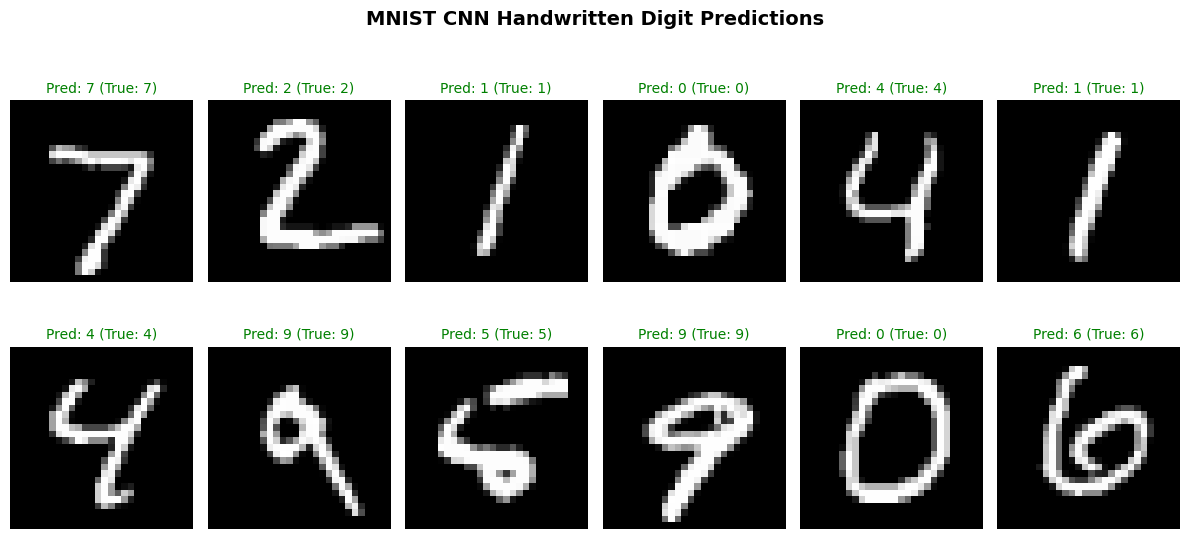

In [4]:
# Visualize 12 Sample Test Predictions
model.eval()
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = model(images)
    preds = outputs.argmax(dim=1)

# Plot Grid
plt.figure(figsize=(12, 6))
for i in range(12):
    plt.subplot(2, 6, i + 1)

    # Un-normalize image for visualization
    img = images[i].cpu().squeeze() * 0.3081 + 0.1307
    plt.imshow(img, cmap='gray')

    pred_label = preds[i].item()
    true_label = labels[i].item()

    color = 'green' if pred_label == true_label else 'red'
    plt.title(f"Pred: {pred_label} (True: {true_label})", color=color, fontsize=10)
    plt.axis('off')

plt.suptitle("MNIST CNN Handwritten Digit Predictions", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()